In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import astropy.units as u
import yaml
import warnings

from astropy.cosmology import FlatLambdaCDM, Planck18
from astropy.io import fits
from pathlib import Path
from astropy.table import Table, join
from scipy.spatial import cKDTree
from scipy.optimize import minimize, minimize_scalar
from scipy.integrate import quad
from scipy.special import beta as beta_function
from scipy.interpolate import griddata

In [2]:
def make_fake_footprint(r_eff, ellip, theta, padding=9.0):
    """Boolean elliptical footprint (semi-major axis = padding * r_eff pixels) and its half-size."""
    a = padding * r_eff
    b = max(a * (1.0 - ellip), 1e-3)
    half = int(np.ceil(a))
    yy, xx = np.mgrid[-half:half + 1, -half:half + 1]
    xr = xx * np.cos(theta) + yy * np.sin(theta)
    yr = -xx * np.sin(theta) + yy * np.cos(theta)
    return np.sqrt((xr / a) ** 2 + (yr / b) ** 2) <= 1.0, half

def make_circular_footprint(r_eff, padding=5.0):
    r = padding * r_eff
    half = int(np.ceil(r))
    yy, xx = np.mgrid[-half:half + 1, -half:half + 1]
    return np.sqrt(xx**2 + yy**2) <= r, half

In [3]:
import numpy as np
import pandas as pd
from astropy.io import fits

# Real source catalogue
cat = pd.read_csv("../inputs/survey/cat_r_eff.csv")

# Set this to your actual segmentation FITS file
seg_path = "../inputs/survey/bundle_sextractor/detection/segmentation_total.fits"
with fits.open(seg_path) as hdul:
    hdul.info()
    seg = hdul[0].data.copy()

depth_path = "../inputs/survey/ceers_f277w_depth_mag.fits"
with fits.open(depth_path) as hdul:
    depth = hdul[0].data.astype(float)

print("Depth shape:", depth.shape)
print("Segmentation shape:", seg.shape)    

Filename: ../inputs/survey/bundle_sextractor/detection/segmentation_total.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       6   (45000, 15400)   int32   
Depth shape: (15400, 45000)
Segmentation shape: (15400, 45000)


Catalogue row: 3
Coordinates: 16643 534
R_eff: 3.342
Labels and pixel counts: {np.int32(0): np.int64(3489), np.int32(22): np.int64(144), np.int32(30): np.int64(80), np.int32(52): np.int64(8)}
Label at source centre: 30


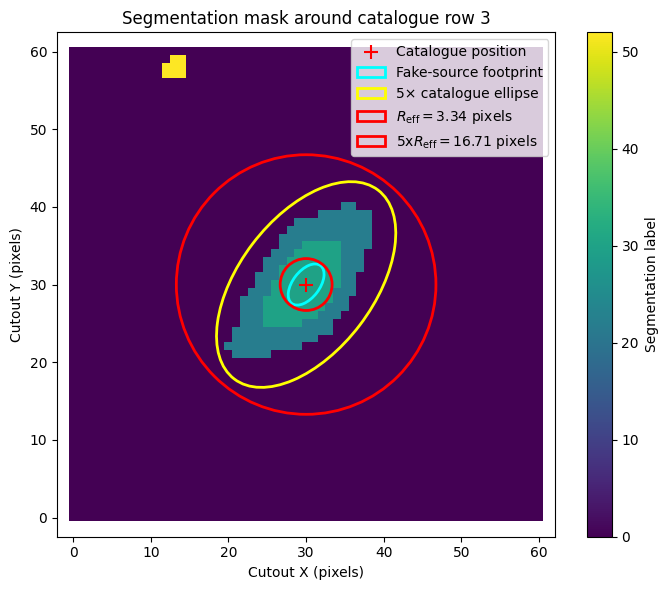

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Ellipse

row_idx = 3
row = cat.iloc[row_idx]

# Catalogue position: convert 1-based image coordinates to 0-based pixels
x = int(round(row["X_IMAGE"])) - 1
y = int(round(row["Y_IMAGE"])) - 1
r_eff = float(row["FLUX_RADIUS"])

a_image = float(row["A_IMAGE"])
b_image = float(row["B_IMAGE"])
theta = float(row["THETA_IMAGE"])
padding = 5

# Calculate ellipticity
ellip = 1.0 - b_image / a_image

# Inspect a region around the source
size = 30
y0, y1 = max(0, y-size), min(seg.shape[0], y+size+1)
x0, x1 = max(0, x-size), min(seg.shape[1], x+size+1)

cutout = seg[y0:y1, x0:x1]

labels, counts = np.unique(cutout, return_counts=True)
print("Catalogue row:", row_idx)
print("Coordinates:", x, y)
print("R_eff:", r_eff)
print("Labels and pixel counts:", dict(zip(labels, counts)))
print("Label at source centre:", seg[y, x])

plt.figure(figsize=(7, 6))
plt.imshow(cutout, origin="lower", interpolation="nearest")
plt.colorbar(label="Segmentation label")
# Catalogue position
plt.scatter(x - x0, y - y0, marker="+", color="red", s=100, label="Catalogue position")
# Circle with radius R_eff
circle_1 = Circle((x - x0, y - y0), radius=r_eff, edgecolor="red", facecolor="none", 
                  linewidth=2, label=fr"$R_{{\rm eff}} = {r_eff:.2f}$ pixels")
padding = 5
circle_2 = Circle((x - x0, y - y0), radius=padding*r_eff, edgecolor="red", facecolor="none", 
                  linewidth=2, label=fr"{padding}x$R_{{\rm eff}} = {padding*r_eff:.2f}$ pixels")

ellipse = Ellipse((x - x0, y - y0), width=2 * a_image, height=2 * b_image, angle=theta, edgecolor="cyan", 
                  facecolor="none", linewidth=2, label="Fake-source footprint")
ellipse_padded = Ellipse((x - x0, y - y0), width=2 * padding * a_image, height=2 * padding * b_image, 
                         angle=theta, edgecolor="yellow", facecolor="none", linewidth=2, label=f"{padding}× catalogue ellipse")

plt.gca().add_patch(ellipse)
plt.gca().add_patch(ellipse_padded)
plt.gca().add_patch(circle_1)
plt.gca().add_patch(circle_2)
plt.xlabel("Cutout X (pixels)")
plt.ylabel("Cutout Y (pixels)")
plt.title(f"Segmentation mask around catalogue row {row_idx}")
plt.legend()
plt.axis("equal")
plt.tight_layout()
plt.show()

In [5]:
def footprint_clear(x, y, r_eff, ellip, theta, segm, depth, padding=9.0):
    """True where the padded elliptical footprint lies fully on covered sky (finite depth)
    and touches no real-source segmentation pixel. Stamps leaving the image are rejected."""
    ny, nx = depth.shape
    ok = np.zeros(len(x), bool)
    for i in range(len(x)):
        ix, iy = int(round(x[i])), int(round(y[i]))
        fp, half = make_fake_footprint(r_eff[i], ellip[i], theta[i], padding=padding)
        y_lo, y_hi, x_lo, x_hi = iy - half, iy + half + 1, ix - half, ix + half + 1
        if y_lo < 0 or x_lo < 0 or y_hi > ny or x_hi > nx:
            continue
        covered = np.isfinite(depth[y_lo:y_hi, x_lo:x_hi][fp]).all()
        clean = not np.any(np.asarray(segm[y_lo:y_hi, x_lo:x_hi])[fp])
        ok[i] = covered and clean
    return ok

In [6]:

import numpy as np
from scipy.spatial import cKDTree


def measure_fake_overlaps(
    x_fake, y_fake, r_eff_fake, ellip_fake, theta_fake,
    segm, depth, padding=9.0
):
    """
    Measure fake-source overlap with real segmentation pixels and
    with other fake-source footprints.

    Returns counts and percentages among in-bounds,
    depth-covered fake-source footprints.
    """

    x_fake = np.asarray(x_fake)
    y_fake = np.asarray(y_fake)
    r_eff_fake = np.asarray(r_eff_fake)
    ellip_fake = np.asarray(ellip_fake)
    theta_fake = np.asarray(theta_fake)

    n = len(x_fake)

    if not all(len(a) == n for a in
               [y_fake, r_eff_fake, ellip_fake, theta_fake]):
        raise ValueError("All fake-source arrays must have equal length.")

    if segm.shape != depth.shape:
        raise ValueError("segmentation and depth maps must have equal shapes.")

    ny, nx = depth.shape

    eligible = np.zeros(n, dtype=bool)
    real_overlap = np.zeros(n, dtype=bool)
    fake_overlap = np.zeros(n, dtype=bool)
    centres = np.full((n, 2), np.nan)
    halves = np.zeros(n, dtype=int)

    # Cache only footprint parameters, not the full image.
    for i in range(n):
        vals = [x_fake[i], y_fake[i], r_eff_fake[i],
                ellip_fake[i], theta_fake[i]]

        if not np.all(np.isfinite(vals)) or r_eff_fake[i] <= 0:
            continue

        ix = int(round(x_fake[i]))
        iy = int(round(y_fake[i]))

        fp, half = make_fake_footprint(
            r_eff_fake[i], ellip_fake[i],
            theta_fake[i], padding=padding
        )

        x0, x1 = ix - half, ix + half + 1
        y0, y1 = iy - half, iy + half + 1

        # Reject footprints crossing image boundaries.
        if x0 < 0 or y0 < 0 or x1 > nx or y1 > ny:
            continue

        depth_cut = depth[y0:y1, x0:x1]
        seg_cut = np.asarray(segm[y0:y1, x0:x1])

        if fp.shape != depth_cut.shape:
            continue

        # Require the entire footprint to lie on covered sky.
        if not np.isfinite(depth_cut[fp]).all():
            continue

        eligible[i] = True
        centres[i] = [ix, iy]
        halves[i] = half

        # Any nonzero segmentation pixel indicates intersection
        # with a real source.
        real_overlap[i] = np.any(seg_cut[fp] != 0)

    # Find fake-fake overlaps using spatial neighbours.
    valid_idx = np.flatnonzero(eligible)

    if len(valid_idx) >= 2:
        tree = cKDTree(centres[valid_idx])
        max_half = int(halves[valid_idx].max())

        # Conservative search radius; exact masks are checked below.
        search_radius = 2 * max_half * np.sqrt(2)

        for i in valid_idx:
            neighbours_local = tree.query_ball_point(
                centres[i], r=search_radius
            )

            for j_local in neighbours_local:
                j = valid_idx[j_local]

                # Count each pair once.
                if j <= i:
                    continue

                # Bounding-box overlap test.
                ix, iy = centres[i].astype(int)
                jx, jy = centres[j].astype(int)
                hi, hj = halves[i], halves[j]

                ax0, ax1 = ix - hi, ix + hi + 1
                ay0, ay1 = iy - hi, iy + hi + 1
                bx0, bx1 = jx - hj, jx + hj + 1
                by0, by1 = jy - hj, jy + hj + 1

                ox0, ox1 = max(ax0, bx0), min(ax1, bx1)
                oy0, oy1 = max(ay0, by0), min(ay1, by1)

                if ox0 >= ox1 or oy0 >= oy1:
                    continue

                fpi, _ = make_fake_footprint(
                    r_eff_fake[i], ellip_fake[i],
                    theta_fake[i], padding=padding
                )
                fpj, _ = make_fake_footprint(
                    r_eff_fake[j], ellip_fake[j],
                    theta_fake[j], padding=padding
                )

                # Convert common image region to local mask coordinates.
                ai = fpi[
                    oy0 - ay0:oy1 - ay0,
                    ox0 - ax0:ox1 - ax0
                ]
                bj = fpj[
                    oy0 - by0:oy1 - by0,
                    ox0 - bx0:ox1 - bx0
                ]

                if np.any(ai & bj):
                    fake_overlap[i] = True
                    fake_overlap[j] = True

    # Summaries
    n_total = n
    n_eligible = int(eligible.sum())
    n_real = int(real_overlap[eligible].sum())
    n_fake = int(fake_overlap[eligible].sum())

    def pct(count, denominator):
        return 100 * count / denominator if denominator else np.nan

    print(f"Total fake sources: {n_total}")
    print(f"In-bounds, depth-covered footprints: {n_eligible}")
    print(f"Rejected / invalid footprints: {n_total - n_eligible}")
    print()
    print("OVERLAP WITH REAL SOURCES")
    print(f"Count: {n_real} / {n_eligible}")
    print(f"Percentage: {pct(n_real, n_eligible):.2f}%")
    print()
    print("OVERLAP WITH OTHER FAKE SOURCES")
    print(f"Count: {n_fake} / {n_eligible}")
    print(f"Percentage: {pct(n_fake, n_eligible):.2f}%")

    return {
        "eligible": eligible,
        "real_overlap": real_overlap,
        "fake_overlap": fake_overlap,
        "n_total": n_total,
        "n_eligible": n_eligible,
        "n_real_overlap": n_real,
        "pct_real_overlap": pct(n_real, n_eligible),
        "n_fake_overlap": n_fake,
        "pct_fake_overlap": pct(n_fake, n_eligible),
    }



In [7]:
# Reproducible random numbers
rng = np.random.default_rng(42)

# Number of fake sources
N_FAKE = 10000

# Image dimensions
ny, nx = seg.shape

# Real-source size and shape distributions
real_valid = (
    np.isfinite(cat["FLUX_RADIUS"].to_numpy()) &
    np.isfinite(cat["A_IMAGE"].to_numpy()) &
    np.isfinite(cat["B_IMAGE"].to_numpy()) &
    np.isfinite(cat["THETA_IMAGE"].to_numpy()) &
    (cat["FLUX_RADIUS"].to_numpy() > 0) &
    (cat["A_IMAGE"].to_numpy() > 0) &
    (cat["B_IMAGE"].to_numpy() > 0)
)

real = cat.loc[real_valid]

# Randomly assign observed source sizes and shapes to fake positions
sample_idx = rng.integers(0, len(real), size=N_FAKE)

r_eff_fake = real["FLUX_RADIUS"].to_numpy()[sample_idx]
a_real = real["A_IMAGE"].to_numpy()[sample_idx]
b_real = real["B_IMAGE"].to_numpy()[sample_idx]
theta_fake = real["THETA_IMAGE"].to_numpy()[sample_idx]

ellip_fake = np.clip(1 - b_real / a_real, 0, 0.95)

# Random pixel positions (zero-based image coordinates)
x_fake = rng.uniform(0, nx, size=N_FAKE)
y_fake = rng.uniform(0, ny, size=N_FAKE)

fake_cat = pd.DataFrame({
    "x": x_fake,
    "y": y_fake,
    "r_eff": r_eff_fake,
    "ellip": ellip_fake,
    "theta": theta_fake
})

print("Fake catalogue created.")
print("Number of fake sources:", len(fake_cat))
print(fake_cat.head())


print("Fake sources:", len(fake_cat))
print("Image dimensions:", nx, "x", ny)
print("Radius range:", fake_cat["r_eff"].min(),
      fake_cat["r_eff"].max())
print("Ellipticity range:", fake_cat["ellip"].min(),
      fake_cat["ellip"].max())

assert np.isfinite(fake_cat[
    ["x", "y", "r_eff", "ellip", "theta"]
].to_numpy()).all()

assert (fake_cat["r_eff"] > 0).all()

assert fake_cat["x"].between(0, nx).all()
assert fake_cat["y"].between(0, ny).all()


results = measure_fake_overlaps(
    x_fake=x_fake,
    y_fake=y_fake,
    r_eff_fake=r_eff_fake,
    ellip_fake=ellip_fake,
    theta_fake=theta_fake,
    segm=seg,
    depth=depth,
    padding=5.0
)


Fake catalogue created.
Number of fake sources: 10000
              x             y  r_eff     ellip  theta
0   9816.713305   5352.346665  2.659  0.209473 -87.37
1  29831.746525   1583.231544  2.345  0.383117  37.24
2  34508.768414   4651.854378  5.508  0.168856 -66.34
3   7498.626436  12423.277825  2.253  0.162865  74.26
4   1973.622754   7599.584808  1.993  0.547511  89.72
Fake sources: 10000
Image dimensions: 45000 x 15400
Radius range: 0.651 33.721
Ellipticity range: 0.0012468827930174342 0.8773471833799441
Total fake sources: 10000
In-bounds, depth-covered footprints: 5294
Rejected / invalid footprints: 4706

OVERLAP WITH REAL SOURCES
Count: 1460 / 5294
Percentage: 27.58%

OVERLAP WITH OTHER FAKE SOURCES
Count: 166 / 5294
Percentage: 3.14%


In [8]:

import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

# ============================================================
# SETTINGS
# ============================================================
PADDING = 5.0
RNG_SEED = 42
N_BRUTE_CHECK = 500

# ============================================================
# 1. INPUT VALIDATION
# ============================================================
x_f = np.asarray(x_fake, dtype=float)
y_f = np.asarray(y_fake, dtype=float)
r_f = np.asarray(r_eff_fake, dtype=float)
e_f = np.asarray(ellip_fake, dtype=float)
t_f = np.asarray(theta_fake, dtype=float)

assert len({len(x_f), len(y_f), len(r_f),
            len(e_f), len(t_f)}) == 1
assert seg.shape == depth.shape

ny, nx = depth.shape
n_fake = len(x_f)

print("=" * 65)
print("FAKE-SOURCE OVERLAP ANALYSIS")
print("=" * 65)
print("Number of fake sources:", n_fake)
print("Image shape:", depth.shape)
print("Padding:", PADDING)

# ============================================================
# 2. CHECK EACH FAKE FOOTPRINT
# ============================================================
eligible = np.zeros(n_fake, dtype=bool)
real_overlap = np.zeros(n_fake, dtype=bool)
centres = np.full((n_fake, 2), np.nan)
halves = np.zeros(n_fake, dtype=int)

# Record why each source is rejected
bad_input = 0
out_of_bounds = 0
bad_depth = 0

for i in range(n_fake):

    values = [x_f[i], y_f[i], r_f[i], e_f[i], t_f[i]]

    if not np.all(np.isfinite(values)) or r_f[i] <= 0:
        bad_input += 1
        continue

    ix = int(round(x_f[i]))
    iy = int(round(y_f[i]))

    fp, half = make_fake_footprint(
        r_f[i], e_f[i], t_f[i], padding=PADDING
    )

    x0, x1 = ix - half, ix + half + 1
    y0, y1 = iy - half, iy + half + 1

    if x0 < 0 or y0 < 0 or x1 > nx or y1 > ny:
        out_of_bounds += 1
        continue

    dcut = depth[y0:y1, x0:x1]
    scut = np.asarray(seg[y0:y1, x0:x1])

    if fp.shape != dcut.shape or fp.shape != scut.shape:
        raise ValueError(f"Footprint shape mismatch at fake source {i}")

    if not np.isfinite(dcut[fp]).all():
        bad_depth += 1
        continue

    eligible[i] = True
    centres[i] = [ix, iy]
    halves[i] = half

    # REAL-SOURCE TEST:
    # Any nonzero segmentation pixel inside the footprint.
    real_overlap[i] = np.any(scut[fp] != 0)

valid_idx = np.flatnonzero(eligible)

print("\n--- Footprint validity ---")
print("Invalid input:", bad_input)
print("Out of image bounds:", out_of_bounds)
print("Invalid depth coverage:", bad_depth)
print("Eligible:", len(valid_idx))

# ============================================================
# 3. FAKE-FAKE OVERLAP USING cKDTREE
# ============================================================
fake_overlap_tree = np.zeros(n_fake, dtype=bool)
overlapping_pairs = []

if len(valid_idx) >= 2:

    tree = cKDTree(centres[valid_idx])

    # Each footprint fits inside a square with half-width `half`.
    # If two footprints intersect, their centre distance cannot
    # exceed sqrt(2) * (half_i + half_j).
    max_half = int(halves[valid_idx].max())
    search_radius = np.sqrt(2) * (2 * max_half)

    candidate_pairs_local = tree.query_pairs(
        r=search_radius,
        output_type="ndarray"
    )

    print("\n--- cKDTree candidate pairs ---")
    print("Candidate pairs:", len(candidate_pairs_local))

    for a, b in candidate_pairs_local:
        i = valid_idx[a]
        j = valid_idx[b]

        ix, iy = centres[i].astype(int)
        jx, jy = centres[j].astype(int)
        hi, hj = halves[i], halves[j]

        # Intersection of the two footprint bounding boxes
        x0 = max(ix - hi, jx - hj)
        x1 = min(ix + hi + 1, jx + hj + 1)
        y0 = max(iy - hi, jy - hj)
        y1 = min(iy + hi + 1, jy + hj + 1)

        if x0 >= x1 or y0 >= y1:
            continue

        # Reconstruct the exact elliptical footprints
        fpi, _ = make_fake_footprint(
            r_f[i], e_f[i], t_f[i], padding=PADDING
        )
        fpj, _ = make_fake_footprint(
            r_f[j], e_f[j], t_f[j], padding=PADDING
        )

        # Crop each mask to the common image region
        ai = fpi[
            y0 - (iy - hi):y1 - (iy - hi),
            x0 - (ix - hi):x1 - (ix - hi)
        ]
        bj = fpj[
            y0 - (jy - hj):y1 - (jy - hj),
            x0 - (jx - hj):x1 - (jx - hj)
        ]

        if np.any(ai & bj):
            fake_overlap_tree[i] = True
            fake_overlap_tree[j] = True
            overlapping_pairs.append((i, j))

n_eligible = int(eligible.sum())
n_real = int(real_overlap[eligible].sum())
n_fake = int(fake_overlap_tree[eligible].sum())

print("\n--- Final overlap results ---")
print(f"Real-source overlap: {n_real}/{n_eligible} "
      f"= {100*n_real/n_eligible:.2f}%" if n_eligible else
      "Real-source overlap: no eligible footprints")

print(f"Fake-fake overlap: {n_fake}/{n_eligible} "
      f"= {100*n_fake/n_eligible:.2f}%" if n_eligible else
      "Fake-fake overlap: no eligible footprints")

print("Number of distinct overlapping fake-fake pairs:",
      len(overlapping_pairs))

# ============================================================
# 4. INDEPENDENT BRUTE-FORCE CONSISTENCY CHECK
# ============================================================
# For a reproducible random subset, compare the cKDTree result
# against direct comparisons with EVERY other eligible source.
# This independently tests whether the tree missed any overlaps.

rng = np.random.default_rng(RNG_SEED)

if len(valid_idx) >= 2:

    n_check = min(N_BRUTE_CHECK, len(valid_idx))
    check_idx = rng.choice(valid_idx, size=n_check, replace=False)

    mismatch_sources = []

    for i in check_idx:

        ix, iy = centres[i].astype(int)
        hi = halves[i]

        fpi, _ = make_fake_footprint(
            r_f[i], e_f[i], t_f[i], padding=PADDING
        )

        brute_overlap = False

        for j in valid_idx:

            if i == j:
                continue

            jx, jy = centres[j].astype(int)
            hj = halves[j]

            # Skip pairs whose bounding boxes cannot intersect
            if abs(ix - jx) > hi + hj:
                continue
            if abs(iy - jy) > hi + hj:
                continue

            x0 = max(ix - hi, jx - hj)
            x1 = min(ix + hi + 1, jx + hj + 1)
            y0 = max(iy - hi, jy - hj)
            y1 = min(iy + hi + 1, jy + hj + 1)

            fpj, _ = make_fake_footprint(
                r_f[j], e_f[j], t_f[j], padding=PADDING
            )

            ai = fpi[
                y0 - (iy - hi):y1 - (iy - hi),
                x0 - (ix - hi):x1 - (ix - hi)
            ]
            bj = fpj[
                y0 - (jy - hj):y1 - (jy - hj),
                x0 - (jx - hj):x1 - (jx - hj)
            ]

            if np.any(ai & bj):
                brute_overlap = True
                break

        if brute_overlap != fake_overlap_tree[i]:
            mismatch_sources.append(i)

    print("\n--- Consistency check ---")
    print("Fake sources checked by brute force:", n_check)
    print("Disagreements with cKDTree:", len(mismatch_sources))

    if mismatch_sources:
        print("Example mismatched indices:", mismatch_sources[:20])
    else:
        print("PASS: cKDTree agrees with brute force for this subset.")

# ============================================================
# 5. SAVE PER-SOURCE RESULTS
# ============================================================
overlap_results = pd.DataFrame({
    "x": x_f,
    "y": y_f,
    "r_eff": r_f,
    "ellip": e_f,
    "theta": t_f,
    "eligible": eligible,
    "real_overlap": real_overlap,
    "fake_overlap": fake_overlap_tree
})

print("\n--- Sanity checks ---")
print("Real overlap count <= eligible:",
      n_real <= n_eligible)
print("Fake overlap count <= eligible:",
      n_fake <= n_eligible)
print("Each fake source counted at most once per category.")




FAKE-SOURCE OVERLAP ANALYSIS
Number of fake sources: 10000
Image shape: (15400, 45000)
Padding: 5.0

--- Footprint validity ---
Invalid input: 0
Out of image bounds: 36
Invalid depth coverage: 4670
Eligible: 5294

--- cKDTree candidate pairs ---
Candidate pairs: 21831

--- Final overlap results ---
Real-source overlap: 1460/5294 = 27.58%
Fake-fake overlap: 166/5294 = 3.14%
Number of distinct overlapping fake-fake pairs: 85

--- Consistency check ---
Fake sources checked by brute force: 500
Disagreements with cKDTree: 0
PASS: cKDTree agrees with brute force for this subset.

--- Sanity checks ---
Real overlap count <= eligible: True
Fake overlap count <= eligible: True
Each fake source counted at most once per category.


Eligible: 5294 | Real overlap: 1460 | Fake-fake overlap: 166


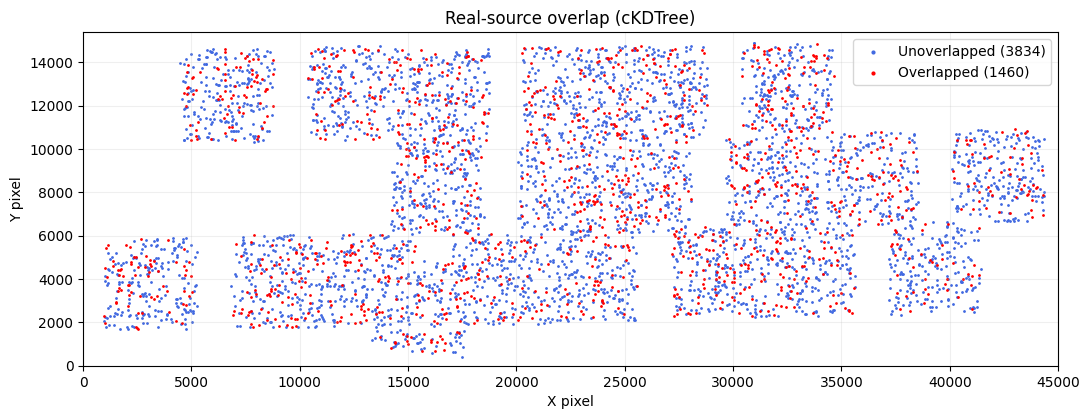

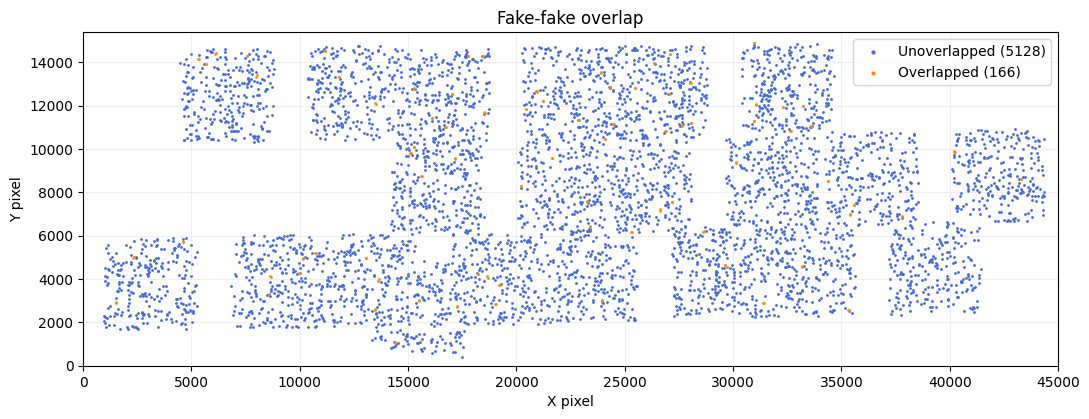

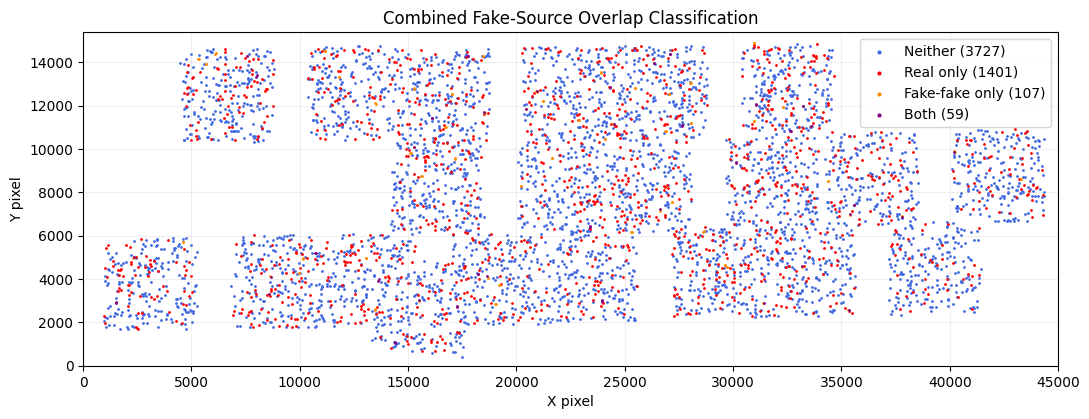

In [18]:

import numpy as np
import matplotlib.pyplot as plt

valid = overlap_results["eligible"].to_numpy(bool)
real = overlap_results["real_overlap"].to_numpy(bool)
fake = overlap_results["fake_overlap"].to_numpy(bool)
x, y = centres[:, 0], centres[:, 1]

masks = [
    (valid & real, valid & ~real, "Real-source overlap (cKDTree)", "red"),
    (valid & fake, valid & ~fake, "Fake-fake overlap", "darkorange")
]

print("Eligible:", valid.sum(), "| Real overlap:", (valid & real).sum(),
      "| Fake-fake overlap:", (valid & fake).sum())

for overlap, unoverlap, title, color in masks:
    fig, ax = plt.subplots(figsize=(11, 8))
    ax.scatter(x[unoverlap], y[unoverlap], s=1, c="royalblue",
               alpha=1.0, label=f"Unoverlapped ({unoverlap.sum()})")
    ax.scatter(x[overlap], y[overlap], s=1, c=color,
               alpha=1.0, label=f"Overlapped ({overlap.sum()})")
    ax.set(xlim=(0, depth.shape[1]), ylim=(0, depth.shape[0]),
           xlabel="X pixel", ylabel="Y pixel", title=title)
    ax.set_aspect("equal")
    ax.legend(markerscale=2)
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

categories = [
    (valid & ~real & ~fake, "Neither", "royalblue"),
    (valid & real & ~fake, "Real only", "red"),
    (valid & ~real & fake, "Fake-fake only", "darkorange"),
    (valid & real & fake, "Both", "purple")
]

fig, ax = plt.subplots(figsize=(11, 8))
for mask, label, color in categories:
    ax.scatter(x[mask], y[mask], s=1, c=color, alpha=1.0,
               label=f"{label} ({mask.sum()})", rasterized=True)

ax.set(xlim=(0, depth.shape[1]), ylim=(0, depth.shape[0]),
       xlabel="X pixel", ylabel="Y pixel",
       title="Combined Fake-Source Overlap Classification")
ax.set_aspect("equal")
ax.legend(markerscale=2)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


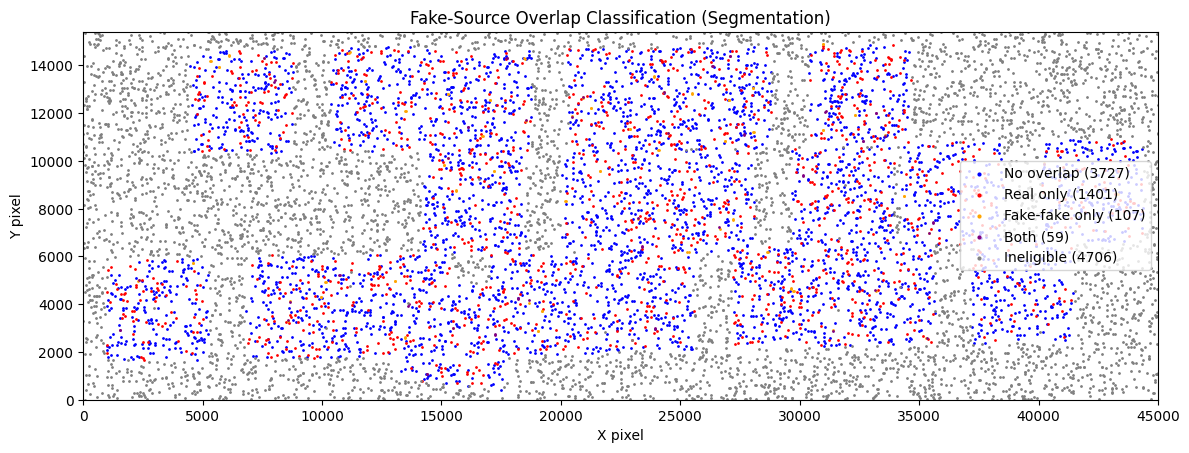

In [19]:
import numpy as np
import matplotlib.pyplot as plt

x, y = np.asarray(x_fake), np.asarray(y_fake)
valid = np.asarray(results["eligible"], bool)
real = np.asarray(results["real_overlap"], bool)
fake = np.asarray(results["fake_overlap"], bool)

masks = [
    (valid & ~real & ~fake, "No overlap", "blue"),
    (valid & real & ~fake, "Real only", "red"),
    (valid & ~real & fake, "Fake-fake only", "orange"),
    (valid & real & fake, "Both", "purple"),
    (~valid, "Ineligible", "gray")
]

fig, ax = plt.subplots(figsize=(12, 8))
for m, label, color in masks:
    ax.scatter(x[m], y[m], s=1, c=color, alpha=1.0, label=f"{label} ({m.sum()})")

ax.set(xlim=(0, seg.shape[1]), ylim=(0, depth.shape[0]),
       xlabel="X pixel", ylabel="Y pixel", title="Fake-Source Overlap Classification (Segmentation)")
ax.set_aspect("equal")
ax.legend(markerscale=2)
plt.tight_layout()
plt.show()

In [11]:

import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

def measure_fake_overlaps(x_fake, y_fake, r_eff_fake, ellip_fake, theta_fake,
                          segm, depth, padding=5.0, footprint_type="elliptical"):
    x, y, r, e, t = [np.asarray(a) for a in
                     (x_fake, y_fake, r_eff_fake, ellip_fake, theta_fake)]
    n, (ny, nx) = len(x), depth.shape
    if segm.shape != depth.shape or any(len(a) != n for a in (y, r, e, t)):
        raise ValueError("Array lengths or image shapes do not match.")

    def fp(i):
        return (make_circular_footprint(r[i], padding=padding) if footprint_type == "circular"
                else make_fake_footprint(r[i], e[i], t[i], padding=padding))

    eligible, real, fake = np.zeros(n, bool), np.zeros(n, bool), np.zeros(n, bool)
    centres, halves, masks = np.full((n, 2), np.nan), np.zeros(n, int), {}

    for i in range(n):
        if not np.all(np.isfinite([x[i], y[i], r[i], e[i], t[i]])) or r[i] <= 0:
            continue
        ix, iy = round(x[i]), round(y[i])
        mask, h = fp(i)
        x0, x1, y0, y1 = ix-h, ix+h+1, iy-h, iy+h+1
        if x0 < 0 or y0 < 0 or x1 > nx or y1 > ny or mask.shape != (2*h+1, 2*h+1):
            continue
        d = depth[y0:y1, x0:x1]
        if not np.isfinite(d[mask]).all():
            continue
        eligible[i], centres[i], halves[i], masks[i] = True, [ix, iy], h, mask
        real[i] = np.any(np.asarray(segm[y0:y1, x0:x1])[mask] != 0)

    ids = np.flatnonzero(eligible)
    if len(ids) > 1:
        tree = cKDTree(centres[ids])
        pairs = tree.query_pairs(2*np.sqrt(2)*halves[ids].max())
        for a, b in pairs:
            i, j = ids[a], ids[b]
            ix, iy = centres[i].astype(int); jx, jy = centres[j].astype(int)
            hi, hj = halves[i], halves[j]
            x0, x1 = max(ix-hi, jx-hj), min(ix+hi+1, jx+hj+1)
            y0, y1 = max(iy-hi, jy-hj), min(iy+hi+1, jy+hj+1)
            if x0 >= x1 or y0 >= y1:
                continue
            ai = masks[i][y0-(iy-hi):y1-(iy-hi), x0-(ix-hi):x1-(ix-hi)]
            bj = masks[j][y0-(jy-hj):y1-(jy-hj), x0-(jx-hj):x1-(jx-hj)]
            if np.any(ai & bj):
                fake[i] = fake[j] = True

    ne = eligible.sum()
    nr, nf = (real & eligible).sum(), (fake & eligible).sum()
    pct = lambda count: 100*count/ne if ne else np.nan
    print(f"{footprint_type}: eligible={ne}/{n}, real overlap={nr} ({pct(nr):.2f}%), "
          f"fake-fake overlap={nf} ({pct(nf):.2f}%)")
    return {"eligible": eligible, "real_overlap": real, "fake_overlap": fake,
            "n_total": n, "n_eligible": int(ne), "n_real_overlap": int(nr),
            "pct_real_overlap": pct(nr), "n_fake_overlap": int(nf),
            "pct_fake_overlap": pct(nf)}


# Compare using identical positions, sizes, and padding
elliptical = measure_fake_overlaps(x_fake, y_fake, r_eff_fake, ellip_fake, theta_fake,
                                   seg, depth, padding=5.0, footprint_type="elliptical")
circular = measure_fake_overlaps(x_fake, y_fake, r_eff_fake, ellip_fake, theta_fake,
                                 seg, depth, padding=5.0, footprint_type="circular")

metrics = ["n_eligible", "n_real_overlap", "pct_real_overlap",
           "n_fake_overlap", "pct_fake_overlap"]
comparison = pd.DataFrame({"Metric": metrics,
    "Elliptical": [elliptical[k] for k in metrics],
    "Circular": [circular[k] for k in metrics]})
comparison["Change"] = comparison["Circular"] - comparison["Elliptical"]
comparison["Relative change (%)"] = 100*comparison["Change"] / comparison["Elliptical"].replace(0, np.nan)
print("\n", comparison.round(3).to_string(index=False))

common = elliptical["eligible"] & circular["eligible"]
for k in ("real_overlap", "fake_overlap"):
    a, b = elliptical[k][common], circular[k][common]
    print(f"{k}: {np.sum(a != b)}/{common.sum()} changed "
          f"({100*np.mean(a != b):.2f}%)" if common.sum() else f"{k}: no common eligible sources")


elliptical: eligible=5294/10000, real overlap=1460 (27.58%), fake-fake overlap=166 (3.14%)
circular: eligible=5264/10000, real overlap=1685 (32.01%), fake-fake overlap=229 (4.35%)

           Metric  Elliptical  Circular  Change  Relative change (%)
      n_eligible    5294.000   5264.00 -30.000               -0.567
  n_real_overlap    1460.000   1685.00 225.000               15.411
pct_real_overlap      27.578     32.01   4.431               16.069
  n_fake_overlap     166.000    229.00  63.000               37.952
pct_fake_overlap       3.136      4.35   1.215               38.738
real_overlap: 237/5264 changed (4.50%)
fake_overlap: 72/5264 changed (1.37%)


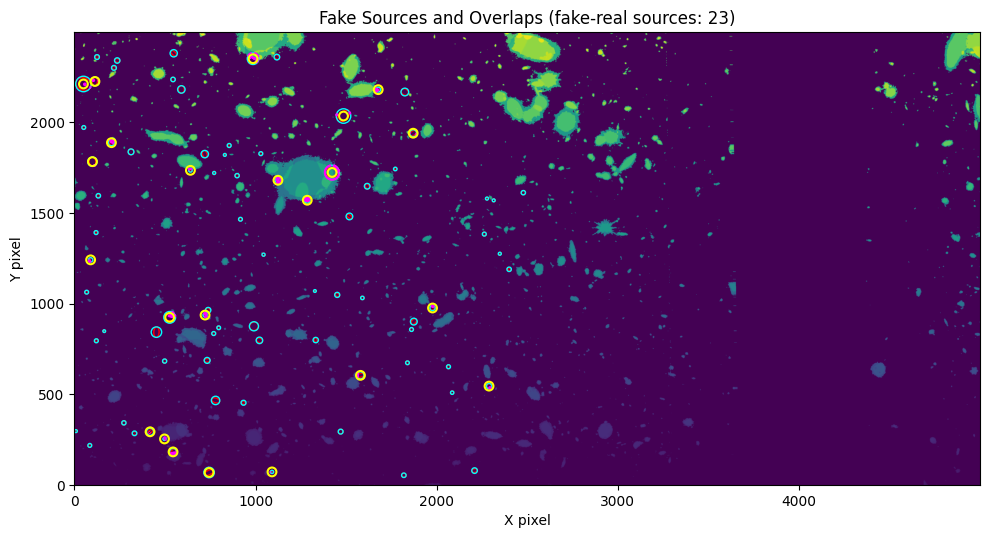

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, Circle

x0, y0, size, padding = 2000, 1500, 2500, 5
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(seg[y0:y0+size, x0:x0+(2*size)], origin="lower", cmap="viridis")

sources = np.where((x_fake >= x0) & (x_fake < x0+size) &
                   (y_fake >= y0) & (y_fake < y0+size))[0]
yy, xx = np.mgrid[y0:y0+size, x0:x0+size]
ell_masks, circ_masks = [], []
found = 0

for i in sources:
    x, y, a = x_fake[i], y_fake[i], padding*r_eff_fake[i]
    e, th = ellip_fake[i], np.deg2rad(theta_fake[i])
    b = a*(1-e)
    dx, dy = xx-x, yy-y
    u, v = dx*np.cos(th)+dy*np.sin(th), -dx*np.sin(th)+dy*np.cos(th)
    em = (u/a)**2+(v/b)**2 <= 1
    cm = dx**2+dy**2 <= a**2
    ell_masks.append(em)
    circ_masks.append(cm)

    ax.add_patch(Ellipse((x-x0, y-y0), 2*a, 2*b,
                         angle=theta_fake[i], fill=False, ec="red", lw=1))
    ax.add_patch(Circle((x-x0, y-y0), a, fill=False, ec="cyan", lw=1))

    xa, xb = max(0, int(x)-int(np.ceil(a))), min(seg.shape[1], int(x)+int(np.ceil(a))+1)
    ya, yb = max(0, int(y)-int(np.ceil(a))), min(seg.shape[0], int(y)+int(np.ceil(a))+1)
    sy, sx = np.mgrid[ya:yb, xa:xb]
    real = seg[ya:yb, xa:xb] != 0
    real_overlap = ((sx-x)**2+(sy-y)**2 <= a**2) & real
    if np.any(real_overlap):
        ax.contour(sx-x0, sy-y0, real_overlap.astype(float),
                   levels=[0.5], colors="magenta", linewidths=1.5)
        ax.scatter(x-x0, y-y0, s=40, facecolors="none",
                   edgecolors="yellow", linewidths=1.5, zorder=10)
        found += 1

for masks, color in [(ell_masks, "yellow"), (circ_masks, "lime")]:
    if len(masks):
        count = np.sum(masks, axis=0)
        ax.contour(count, levels=[1.5], colors=color, linewidths=1.5)

ax.set(xlabel="X pixel", ylabel="Y pixel",
       title=f"Fake Sources and Overlaps (fake-real sources: {found})")
plt.tight_layout()
plt.show()

In [2]:
def make_zM_sampler(z_grid, M_grid, phi, cosmo=Planck18):
    """Returns sample(rng, n) -> (z, M), drawn from dV/dz * phi(M, z) on the grids."""
    dVdz = cosmo.differential_comoving_volume(z_grid).value
    w = np.array([dVdz[j] * phi(M_grid, z) for j, z in enumerate(z_grid)])     # (n_z, n_M)
    p = (w / w.sum()).ravel()
    dz, dM = np.gradient(z_grid), np.gradient(M_grid)

    def sample(rng, n):
        j, i = np.divmod(rng.choice(p.size, size=n, p=p), len(M_grid))
        z = z_grid[j] + rng.uniform(-0.5, 0.5, n) * dz[j]                      # jitter inside the cell
        M = M_grid[i] + rng.uniform(-0.5, 0.5, n) * dM[i]
        return z, M
    return sample

def make_phi():
    M_star, log_phi_star, alpha = -20.82, -3.92, -2.16
    phi_star = 10**log_phi_star

    def phi(M, z):
        x = 10**(0.4 * (M_star - np.asarray(M)))
        return 0.4 * np.log(10) * phi_star * x**(alpha + 1) * np.exp(-x)

    return phi

z_grid: [ 7.5  8.5  9.5 10.5 11.5 12.5]
M_grid: [-24.  -23.9 -23.8 -23.7 -23.6] ... [-16.4 -16.3 -16.2 -16.1 -16. ]
phi shape: (81,)


Weight matrix shape: (6, 81)
Minimum/maximum: 0.000453804133508593 486115759.5858063
All finite and non-negative: True


Number of probabilities: 486
Sum: 1.0
Minimum/maximum: 2.039535847474185e-14 0.02184754268393241


Sample shapes: (10000,) (10000,)
z range: 7.500006584278104 12.499738807014397
M range: -21.644346707136037 -16.000105738655535


2D chi-square vs expected cell probabilities: chi2 = 284.4, dof = 485, p-value = 1.000


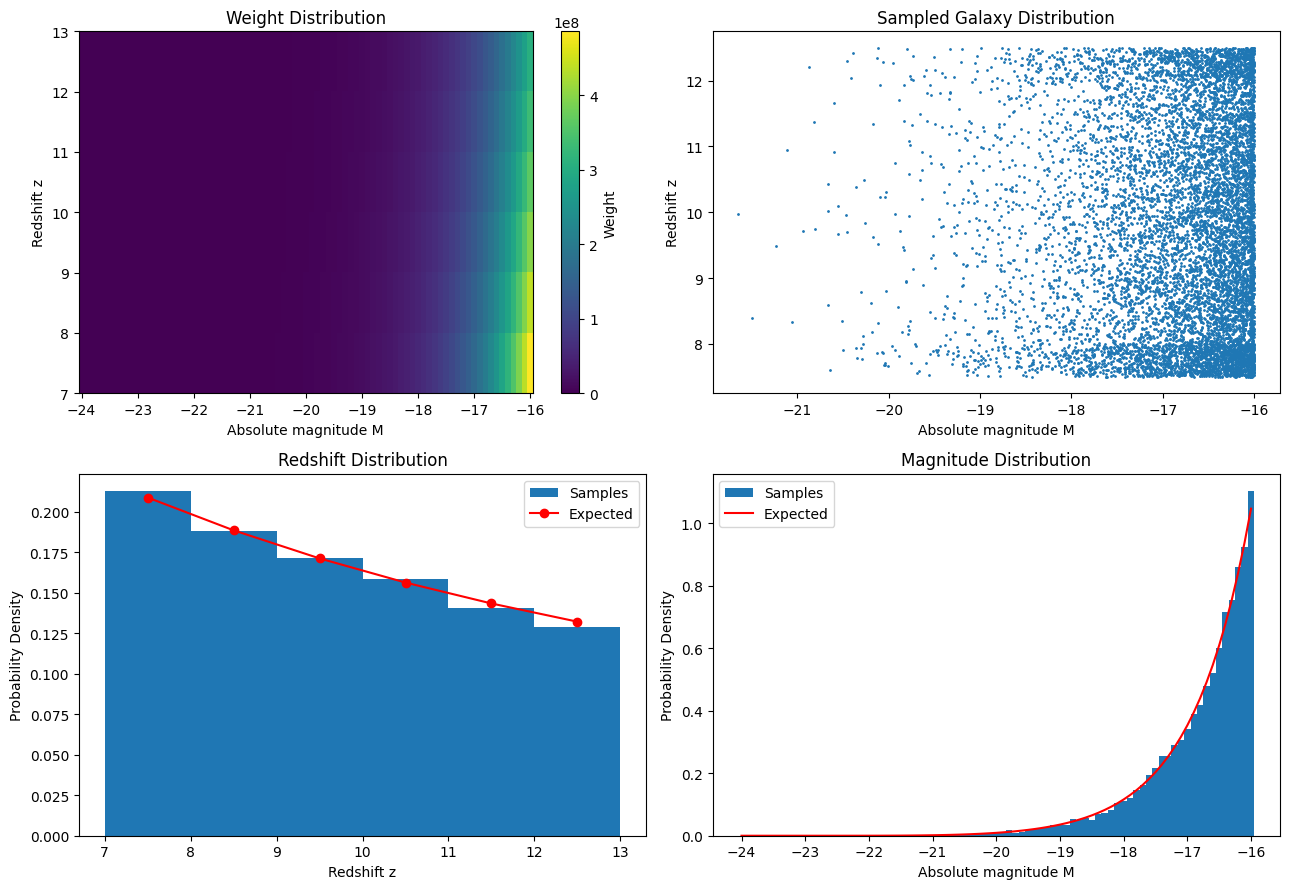

In [16]:
# Input data 
z_grid = np.linspace(7.5, 12.5, 6)
M_grid = np.linspace(-24, -16, 81)
phi = make_phi()

print("z_grid:", z_grid)
print("M_grid:", M_grid[:5], "...", M_grid[-5:])
print("phi shape:", np.shape(phi(M_grid, z_grid[0])))

# weight matrix
dVdz = Planck18.differential_comoving_volume(z_grid).value
w = np.array([dVdz[j] * phi(M_grid, z) for j, z in enumerate(z_grid)])

print("\n\nWeight matrix shape:", w.shape)
print("Minimum/maximum:", w.min(), w.max())
print("All finite and non-negative:", np.isfinite(w).all() and (w >= 0).all())


p = (w / w.sum()).ravel()
print("\n\nNumber of probabilities:", p.size)
print("Sum:", p.sum())
print("Minimum/maximum:", p.min(), p.max())

sampler = make_zM_sampler(z_grid, M_grid, phi)
rng = np.random.default_rng(42)
z, M = sampler(rng, 10_000)

print("\n\nSample shapes:", z.shape, M.shape)
print("z range:", z.min(), z.max())
print("M range:", M.min(), M.max())

# Grid nodes are cell CENTRES: each sample lies within node +- half a cell
dz, dM = np.gradient(z_grid), np.gradient(M_grid)
z_edges = np.r_[z_grid - dz/2, z_grid[-1] + dz[-1]/2]
M_edges = np.r_[M_grid - dM/2, M_grid[-1] + dM[-1]/2]

# Quantitative check: sampled counts per cell vs expected N * p
from scipy.stats import chisquare
H, _, _ = np.histogram2d(z, M, bins=[z_edges, M_edges])
chi2, pval = chisquare(H.ravel(), p * len(z))
print(f"\n\n2D chi-square vs expected cell probabilities: chi2 = {chi2:.1f}, dof = {p.size - 1}, p-value = {pval:.3f}")

fig, ax = plt.subplots(2, 2, figsize=(13, 9))

im = ax[0, 0].imshow(w, origin="lower", aspect="auto", extent=[M_edges[0], M_edges[-1], z_edges[0], z_edges[-1]])
ax[0, 0].set(xlabel="Absolute magnitude M", ylabel="Redshift z", title="Weight Distribution")
fig.colorbar(im, ax=ax[0, 0], label="Weight")

ax[0, 1].scatter(M, z, s=1, alpha=1.0)
ax[0, 1].set(xlabel="Absolute magnitude M", ylabel="Redshift z", title="Sampled Galaxy Distribution")

ax[1, 0].hist(z, bins=z_edges, density=True, alpha=1.0, label="Samples")
ax[1, 0].plot(z_grid, (w.sum(axis=1)/w.sum()) / dz, "ro-", label="Expected")
ax[1, 0].set(xlabel="Redshift z", ylabel="Probability Density", title="Redshift Distribution")
ax[1, 0].legend()

ax[1, 1].hist(M, bins=M_edges, density=True, alpha=1.0, label="Samples")
ax[1, 1].plot(M_grid, (w.sum(axis=0)/w.sum()) / dM, "r-", label="Expected")
ax[1, 1].set(xlabel="Absolute magnitude M", ylabel="Probability Density", title="Magnitude Distribution")
ax[1, 1].legend()

plt.tight_layout()
plt.show()

In [6]:
def make_randoms_cells(depth, z_grid, M_grid, C, phi, m_ref, M_edges, n_target,
                       seed=0, chunk=500000, max_chunks=2000,
                       valid=None, segm=None, r_eff_values=None, padding=5.0, cosmo=Planck18):
    """depth   : float (ny, nx) relative depth map, NaN where there is no coverage
    M_edges : edges of the M_UV bins, bright -> faint, e.g. [-22, -19.5, -18]
    n_target: list, 20 * N_data for each M bin (data counted in this z-bin AND this M bin)
    valid   : optional bool mask (e.g. from make_depth_map.py: coverage and off real sources)
    segm    : real segmentation map -> turns on the size-aware blending check (then do NOT
              also pass a `valid` that is already masked by segmentation); needs r_eff_values,
              the observed size distribution (pixels) for this z-bin
    returns : list (one per M bin) of dicts with x, y, z, M (pixel coordinates, true z and M)"""
    rng = np.random.default_rng(seed)
    sample = make_zM_sampler(z_grid, M_grid, phi, cosmo)
    ny, nx = depth.shape
    nb = len(M_edges) - 1
    n_target = np.asarray(n_target)
    keys = ("x", "y", "z", "M")
    out = [{k: [] for k in keys} for _ in range(nb)]
    have = np.zeros(nb, int)

    for _ in range(max_chunks):
        x = rng.uniform(-0.5, nx - 0.5, chunk)
        y = rng.uniform(-0.5, ny - 0.5, chunk)
        ix, iy = np.floor(x + 0.5).astype(int), np.floor(y + 0.5).astype(int)
        d = depth[iy, ix]
        ok = np.isfinite(d) if valid is None else (valid[iy, ix] & np.isfinite(d))
        x, y, d = x[ok], y[ok], d[ok]

        z, M = sample(rng, len(x))                                       # true z and M
        p = np.clip(C(M - (d - m_ref), z), 0.0, 1.0)                     # depth-aware selection
        keep = rng.random(len(x)) < p
        x, y, z, M = x[keep], y[keep], z[keep], M[keep]

        k = np.digitize(M, M_edges) - 1
        use = (k >= 0) & (k < nb)
        use &= (have < n_target)[np.clip(k, 0, nb - 1)]                  # skip bins already full
        x, y, z, M, k = x[use], y[use], z[use], M[use], k[use]

        if segm is not None and len(x):
            r = rng.choice(r_eff_values, len(x))
            e = rng.uniform(0.0, 0.6, len(x))
            t = rng.uniform(0.0, np.pi, len(x))
            good = footprint_clear(x, y, r, e, t, segm, depth, padding)
            x, y, z, M, k = x[good], y[good], z[good], M[good], k[good]

        for b in range(nb):
            s = k == b
            for key, arr in zip(keys, (x, y, z, M)):
                out[b][key].append(arr[s])
            have[b] += s.sum()
        if np.all(have >= n_target):
            break
    else:
        raise RuntimeError(f"only {have} of {n_target} randoms: check depth map / C / phi / M_grid")

    return [{key: np.concatenate(v)[:n_target[b]] for key, v in out[b].items()} for b in range(nb)]


def make_zM_sampler(z_grid, M_grid, phi, cosmo=Planck18):
    """Sample (z, M) from dV/dz * phi(M,z), using grid-cell centres."""

    z_grid = np.asarray(z_grid, dtype=float)
    M_grid = np.asarray(M_grid, dtype=float)

    if len(z_grid) < 2 or len(M_grid) < 2:
        raise ValueError("z_grid and M_grid must each contain at least 2 points.")
    if np.any(np.diff(z_grid) <= 0) or np.any(np.diff(M_grid) <= 0):
        raise ValueError("z_grid and M_grid must be strictly increasing.")

    dVdz = cosmo.differential_comoving_volume(z_grid).value
    w = np.array([dVdz[j] * phi(M_grid, z) for j, z in enumerate(z_grid)])

    if w.shape != (len(z_grid), len(M_grid)):
        raise ValueError("phi must return one value per magnitude in M_grid.")
    if np.any(~np.isfinite(w)) or np.any(w < 0) or w.sum() <= 0:
        raise ValueError("Sampling weights must be finite, non-negative, and have positive sum.")

    p = (w / w.sum()).ravel()

    # Cell edges: midpoints between grid centres.
    z_edges = np.empty(len(z_grid) + 1)
    z_edges[1:-1] = 0.5 * (z_grid[:-1] + z_grid[1:])
    z_edges[0] = z_grid[0]
    z_edges[-1] = z_grid[-1]

    M_edges_grid = np.empty(len(M_grid) + 1)
    M_edges_grid[1:-1] = 0.5 * (M_grid[:-1] + M_grid[1:])
    M_edges_grid[0] = M_grid[0]
    M_edges_grid[-1] = M_grid[-1]

    def sample(rng, n):
        flat_idx = rng.choice(p.size, size=n, p=p)
        j, i = np.divmod(flat_idx, len(M_grid))

        z = rng.uniform(z_edges[j], z_edges[j + 1])
        M = rng.uniform(M_edges_grid[i], M_edges_grid[i + 1])

        return z, M

    return sample


In [12]:

import numpy as np
import matplotlib.pyplot as plt

ny, nx = 200, 200
depth_test = np.full((ny, nx), 0.5, dtype=float)

phi_test = make_phi()

def C_test(M, z):
    return np.ones(np.broadcast_arrays(M, z)[0].shape)

z_grid = np.linspace(8.0, 10.0, 30)
M_grid = np.linspace(-22.0, -16.0, 200)
M_edges = np.array([-22.0, -20.0, -18.0, -16.0])
print("M_edges = ", M_edges)
# Request 100 random galaxies in each magnitude bin
n_target = np.array([100, 100, 100])

randoms = make_randoms_cells(depth=depth_test, z_grid=z_grid, M_grid=M_grid, C=C_test,
    phi=phi_test, m_ref=0.0, M_edges=M_edges, n_target=n_target, seed=42, chunk=10000, max_chunks=100)

print("Number of magnitude bins:", len(randoms))

for b, cat in enumerate(randoms):
    print(f"\nMagnitude bin {b}: [{M_edges[b]}, {M_edges[b+1]})")
    print("Number generated:", len(cat["M"]))
    print("Number of x coordinates:", len(cat["x"]))
    print("Number of y coordinates:", len(cat["y"]))
    print("Number of redshifts:", len(cat["z"]))
    print("Number of magnitudes:", len(cat["M"]))

    assert len(cat["M"]) == n_target[b]
    assert len(cat["x"]) == n_target[b]
    assert len(cat["y"]) == n_target[b]
    assert len(cat["z"]) == n_target[b]

    assert np.all((cat["x"] >= -0.5) & (cat["x"] < nx - 0.5))
    assert np.all((cat["y"] >= -0.5) & (cat["y"] < ny - 0.5))
    assert np.all((cat["M"] >= M_edges[b]) & (cat["M"] < M_edges[b+1]))
    assert np.all((cat["z"] >= z_grid.min()) & (cat["z"] <= z_grid.max()))

print("\nAll basic checks passed!")


M_edges =  [-22. -20. -18. -16.]
Number of magnitude bins: 3

Magnitude bin 0: [-22.0, -20.0)
Number generated: 100
Number of x coordinates: 100
Number of y coordinates: 100
Number of redshifts: 100
Number of magnitudes: 100

Magnitude bin 1: [-20.0, -18.0)
Number generated: 100
Number of x coordinates: 100
Number of y coordinates: 100
Number of redshifts: 100
Number of magnitudes: 100

Magnitude bin 2: [-18.0, -16.0)
Number generated: 100
Number of x coordinates: 100
Number of y coordinates: 100
Number of redshifts: 100
Number of magnitudes: 100

All basic checks passed!


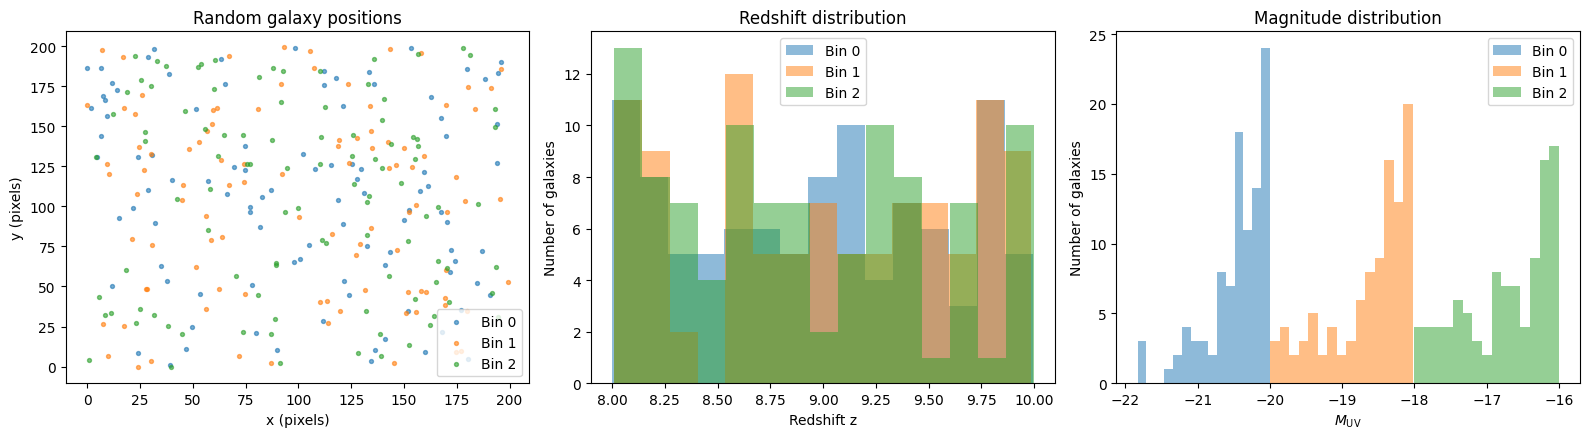

In [13]:

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Spatial positions
for b, cat in enumerate(randoms):
    axes[0].scatter(cat["x"], cat["y"], s=8, alpha=0.6, label=f"Bin {b}")

axes[0].set_xlabel("x (pixels)")
axes[0].set_ylabel("y (pixels)")
axes[0].set_title("Random galaxy positions")
axes[0].legend()

# Redshift distribution
for b, cat in enumerate(randoms):
    axes[1].hist(cat["z"], bins=15, alpha=0.5,label=f"Bin {b}")

axes[1].set_xlabel("Redshift z")
axes[1].set_ylabel("Number of galaxies")
axes[1].set_title("Redshift distribution")
axes[1].legend()

# Absolute magnitude distribution
for b, cat in enumerate(randoms):
    axes[2].hist(cat["M"], bins=15, alpha=0.5, label=f"Bin {b}")

axes[2].set_xlabel(r"$M_{\rm UV}$")
axes[2].set_ylabel("Number of galaxies")
axes[2].set_title("Magnitude distribution")
axes[2].legend()

plt.tight_layout()
plt.show()


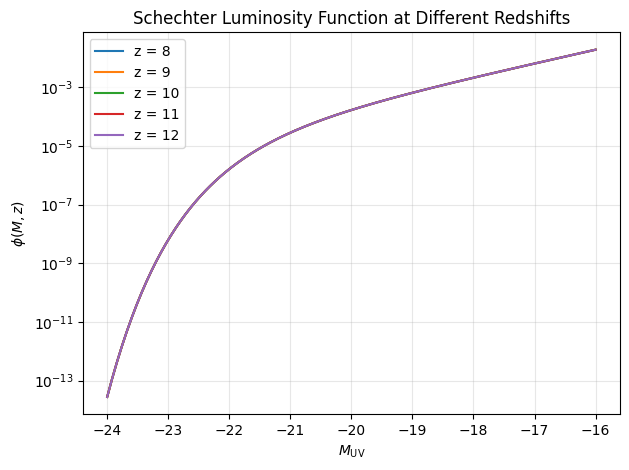

In [15]:
phi = make_phi()
M = np.linspace(-24, -16, 300)
redshifts = [8, 9, 10, 11, 12]

for z in redshifts:
    plt.plot(M, phi(M, z), label=f"z = {z}")

plt.yscale("log")
plt.xlabel(r"$M_{\rm UV}$")
plt.ylabel(r"$\phi(M,z)$")
plt.title("Schechter Luminosity Function at Different Redshifts")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
def _tengent_plane(ra, dec, ra0, dec0):
    return np.column_stack([(np.asarray(ra) - ra0) * np.cos(np.radian(dec0)) * 3600.0, (np.asarray(dec) - dec0) * 3600.0])

def pair_counts(ra1, dec1, ra2, dec2, theta_bins_arcsec, same_catalog=False, ra0=None, dec0=None, **_):
    if ra0 is None:
        ra0 = np.mean(np.concatenate([ra1, ra2]))

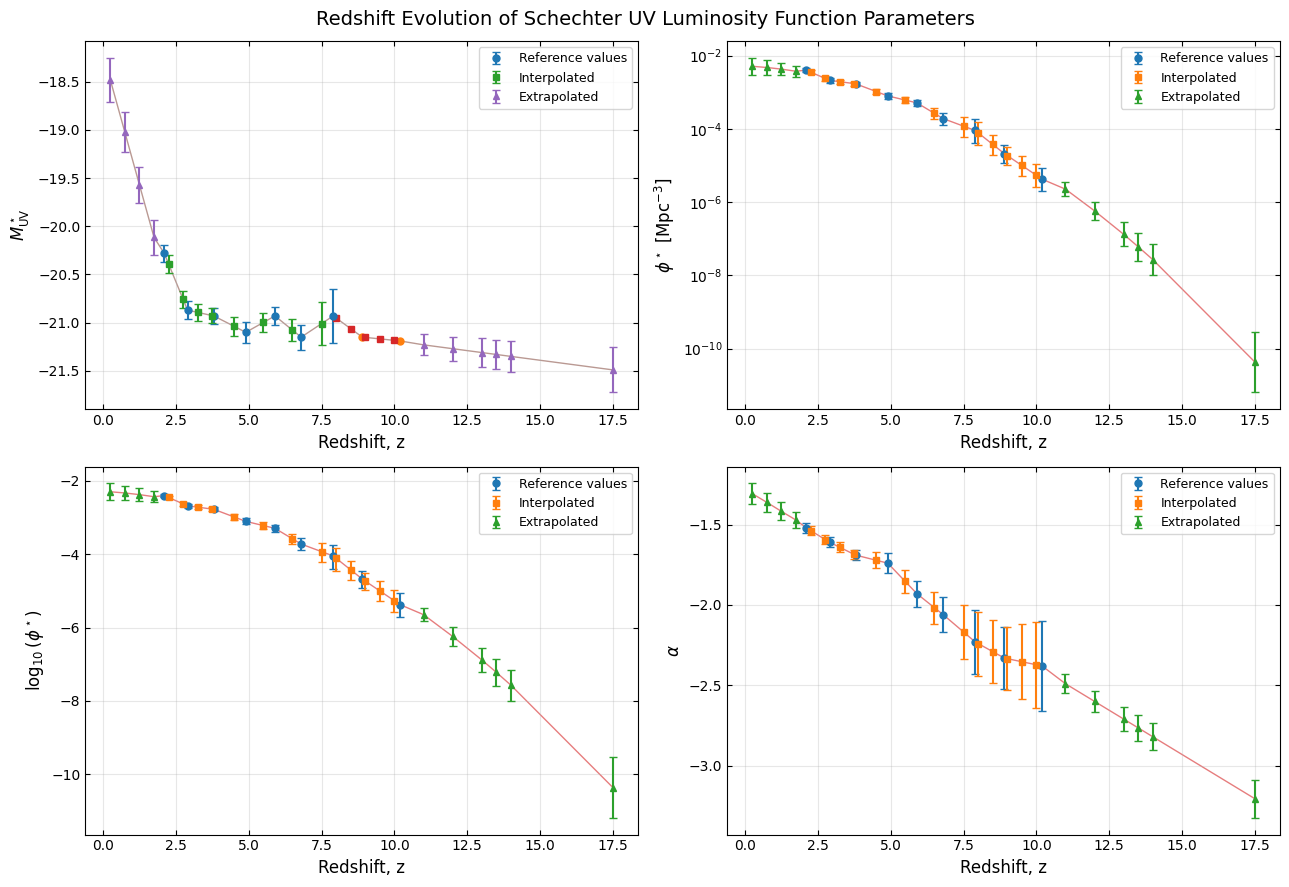

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# If your table is already a DataFrame named df, skip this line.
# Otherwise, load your tab-separated file:
df = pd.read_csv("../inputs/lf_table.csv")

# Sort by redshift
df = df.sort_values("z").copy()

# Convert relevant columns to numeric
columns = ["z", "M_star", "M_star_err_lo", "M_star_err_hi",
            "phi_star", "phi_star_err_lo", "phi_star_err_hi",
            "log_phi_star", "log_phi_star_err_lo", "log_phi_star_err_hi",
            "alpha", "alpha_err_lo", "alpha_err_hi"]

for col in columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Plot settings: (parameter, lower error, upper error, y-axis label)
parameters = [("M_star", "M_star_err_lo", "M_star_err_hi", r"$M^\star_{\rm UV}$"),
              ("phi_star", "phi_star_err_lo", "phi_star_err_hi", r"$\phi^\star\ [{\rm Mpc}^{-3}]$"),
              ("log_phi_star", "log_phi_star_err_lo", "log_phi_star_err_hi", r"$\log_{10}(\phi^\star)$"),
              ("alpha", "alpha_err_lo", "alpha_err_hi", r"$\alpha$")]

# Distinguish the three types of rows
styles = {"real": {"marker": "o", "linestyle": "none", "label": "Reference values"},
          "interpolated": {"marker": "s", "linestyle": "none", "label": "Interpolated"},
          "extrapolated": {"marker": "^", "linestyle": "none", "label": "Extrapolated"}}

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for ax, (ycol, elo, ehi, ylabel) in zip(axes, parameters):

    for row_type, style in styles.items():
        subset = df[df["type"] == row_type]

        # Keep only rows with valid parameter values
        valid = subset[ycol].notna() & subset["z"].notna()
        subset = subset.loc[valid]

        if subset.empty:
            continue
        # Error bars are optional; missing errors are plotted without bars
        err_valid = (subset[elo].notna() & subset[ehi].notna() & (subset[elo] >= 0) & (subset[ehi] >= 0))

        # Plot points that have uncertainties
        with_err = subset.loc[err_valid]
        if not with_err.empty:
            ax.errorbar(with_err["z"], with_err[ycol], yerr=np.vstack([with_err[elo].to_numpy(), with_err[ehi].to_numpy()]), 
                        fmt=style["marker"], linestyle="none", capsize=3, markersize=5, label=style["label"], zorder=3)

        # Plot points without uncertainties
        without_err = subset.loc[~err_valid]
        if not without_err.empty:
            ax.plot(without_err["z"], without_err[ycol], marker=style["marker"], linestyle="none", markersize=5, label=style["label"] if with_err.empty else None, zorder=3)

    # Connect the parameter values to show redshift evolution
    valid_all = df[["z", ycol]].dropna().sort_values("z")
    ax.plot(valid_all["z"], valid_all[ycol], linestyle="-", linewidth=1, alpha=0.6, zorder=1)
    ax.set_xlabel("Redshift, z", fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.grid(True, alpha=0.3)
    ax.tick_params(direction="in", top=True, right=True)

    # Only phi_star is plotted logarithmically
    if ycol == "phi_star":
        ax.set_yscale("log")
    ax.legend(fontsize=9)

fig.suptitle("Redshift Evolution of Schechter UV Luminosity Function Parameters", fontsize=14)
plt.tight_layout()
# plt.savefig("schechter_parameters_vs_redshift.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
z_grid = [8.0, 9.0, 10.0, 11.0, 12.0]
for z in z_grid:
    path = f"../inputs/bins/CEERS_z{z:.2f}_selected.csv"
    df = pd.read_csv(path)
    print(f"{z}, {len(df)}")
path = "../inputs/survey/cat_r_eff.csv" 
df = pd.read_csv(path) 

8.0, 846
9.0, 323
10.0, 53
11.0, 120
12.0, 70


In [20]:
import pandas as pd
import numpy as np

# Load catalogue
catalog = pd.read_csv("../inputs/survey/cat_r_eff.csv")

# Check available columns

print(catalog.columns.tolist())

# Extract redshifts
z_values = pd.to_numeric(catalog["z_a"], errors="coerce").to_numpy()

# Count sources in redshift ranges [z - 0.5, z + 0.5)
for z in [8, 9, 10, 11, 12]:
    mask = (
        np.isfinite(z_values)
        & (z_values >= z - 0.5)
        & (z_values < z + 0.5)
    )
    print(f"{z - 0.5} <= z < {z + 0.5}: {mask.sum()} sources")

['ID', 'z_a', 'chi2_min', 'dchi2', 'intP_highz', 'P_lowz', 'odds', 'nfilt', 'chi2_red', 'RA', 'DEC', 'X_IMAGE', 'Y_IMAGE', 'MODE', 'ID_sex', 'RA_sex', 'DEC_sex', 'X_IMAGE_sex', 'Y_IMAGE_sex', 'A_IMAGE', 'B_IMAGE', 'THETA_IMAGE', 'KRON_RADIUS', 'FLUX_RADIUS', 'CLASS_STAR', 'MODE_sex', 'IN_FOOTPRINT', 'APCORR', 'STAR_FLAG', 'BAD_REGION_FLAG', 'USE', 'FTOT_f606w', 'FTOTERR_f606w', 'MAG_f606w', 'SN_f606w', 'FTOT_f814w', 'FTOTERR_f814w', 'MAG_f814w', 'SN_f814w', 'FTOT_f115w', 'FTOTERR_f115w', 'MAG_f115w', 'SN_f115w', 'FTOT_f150w', 'FTOTERR_f150w', 'MAG_f150w', 'SN_f150w', 'FTOT_f200w', 'FTOTERR_f200w', 'MAG_f200w', 'SN_f200w', 'FTOT_f277w', 'FTOTERR_f277w', 'MAG_f277w', 'SN_f277w', 'FTOT_f356w', 'FTOTERR_f356w', 'MAG_f356w', 'SN_f356w', 'FTOT_f410m', 'FTOTERR_f410m', 'MAG_f410m', 'SN_f410m', 'FTOT_f444w', 'FTOTERR_f444w', 'MAG_f444w', 'SN_f444w', 'match_dist_pix']
7.5 <= z < 8.5: 1012 sources
8.5 <= z < 9.5: 376 sources
9.5 <= z < 10.5: 66 sources
10.5 <= z < 11.5: 144 sources
11.5 <= z < 1

In [27]:
import pandas as pd
import numpy as np
from pathlib import Path

# Input and output paths
input_path = Path("../inputs/survey/cat_r_eff.csv")
output_dir = Path("../inputs/bins")
output_dir.mkdir(parents=True, exist_ok=True)

# Redshift bin edges
BIN_EDGES = np.array(
    [7.5, 8.5, 9.5, 10.5, 11.5, 12.5],
    dtype=float
)

# Load catalogue
catalog = pd.read_csv(input_path)

# Convert redshift column to numeric
catalog["z_a"] = pd.to_numeric(catalog["z_a"], errors="coerce")

# Keep rows with finite redshifts
valid = np.isfinite(catalog["z_a"])

print(f"Total sources: {len(catalog)}")
print(f"Sources with valid redshifts: {valid.sum()}\n")

# Divide and save each redshift bin
for z_lo, z_hi in zip(BIN_EDGES[:-1], BIN_EDGES[1:]):

    # Select sources in [z_lo, z_hi)
    mask = valid & (catalog["z_a"] >= z_lo) & (catalog["z_a"] < z_hi)
    df_bin = catalog.loc[mask].copy()

    # Calculate average redshift of the selected sources
    z_average = df_bin["z_a"].mean()

    # Skip empty bins
    if df_bin.empty:
        print(f"{z_lo} <= z < {z_hi}: No sources found")
        continue

    # Output filename
    filename = f"CEERS_z{z_average:.2f}_selected.csv"
    output_path = output_dir / filename

    # Save catalogue
    df_bin.to_csv(output_path, index=False)

    print(
        f"{z_lo} <= z < {z_hi}: "
        f"{len(df_bin)} sources | "
        f"z_average = {z_average:.2f} | "
        f"Saved: {output_path}"
    )

Total sources: 69214
Sources with valid redshifts: 69214

7.5 <= z < 8.5: 1012 sources | z_average = 8.07 | Saved: ../inputs/bins/CEERS_z8.07_selected.csv
8.5 <= z < 9.5: 376 sources | z_average = 8.90 | Saved: ../inputs/bins/CEERS_z8.90_selected.csv
9.5 <= z < 10.5: 66 sources | z_average = 10.19 | Saved: ../inputs/bins/CEERS_z10.19_selected.csv
10.5 <= z < 11.5: 144 sources | z_average = 11.01 | Saved: ../inputs/bins/CEERS_z11.01_selected.csv
11.5 <= z < 12.5: 89 sources | z_average = 11.85 | Saved: ../inputs/bins/CEERS_z11.85_selected.csv


In [29]:
import pandas as pd
import numpy as np
from pathlib import Path
from astropy.cosmology import Planck18

input_dir = Path("../inputs/bins")

for file in sorted(input_dir.glob("CEERS_z*_selected.csv")):
    df = pd.read_csv(file)
    z = float(file.name.split("_z")[1].split("_")[0])
    mag_col = "MAG_f150w" if z < 10 else "MAG_f200w"

    if mag_col not in df.columns:
        print(f"Skipping {file.name}: missing {mag_col}")
        continue

    m = pd.to_numeric(df[mag_col], errors="coerce")
    df["M_UV"] = m - Planck18.distmod(z).value + 2.5 * np.log10(1 + z)
    df.to_csv(file, index=False)

    print(f"{file.name}: z={z:g}, filter={mag_col}, "
          f"valid M_UV={df['M_UV'].notna().sum()}/{len(df)}")

Skipping CEERS_z0.25_selected.csv: missing MAG_f150w
Skipping CEERS_z0.75_selected.csv: missing MAG_f150w
Skipping CEERS_z1.25_selected.csv: missing MAG_f150w
Skipping CEERS_z1.75_selected.csv: missing MAG_f150w
CEERS_z10.00_selected.csv: z=10, filter=MAG_f200w, valid M_UV=53/53
CEERS_z10.19_selected.csv: z=10.19, filter=MAG_f200w, valid M_UV=66/66
CEERS_z11.00_selected.csv: z=11, filter=MAG_f200w, valid M_UV=120/120
CEERS_z11.01_selected.csv: z=11.01, filter=MAG_f200w, valid M_UV=144/144
CEERS_z11.85_selected.csv: z=11.85, filter=MAG_f200w, valid M_UV=89/89
CEERS_z12.00_selected.csv: z=12, filter=MAG_f200w, valid M_UV=70/70
Skipping CEERS_z13.00_selected.csv: missing MAG_f200w
Skipping CEERS_z13.50_selected.csv: missing MAG_f200w
Skipping CEERS_z14.00_selected.csv: missing MAG_f200w
Skipping CEERS_z17.50_selected.csv: missing MAG_f200w
Skipping CEERS_z2.25_selected.csv: missing MAG_f150w
Skipping CEERS_z2.75_selected.csv: missing MAG_f150w
Skipping CEERS_z3.25_selected.csv: missing MA

In [1]:
def bouwens21_fit(z):
    """Value and symmetric 1-sigma error of M_star, log_phi_star, alpha."""
    if z < 2.46:
        Mstar = -20.89 - 1.09 * (z - 2.46)
        Mstar_err = np.sqrt(0.12 ** 2 + (0.07 * (z - 2.46)) ** 2 + (1.09 * 0.11) ** 2)
    else:
        Mstar = -21.03 - 0.04 * (z - 6)
        Mstar_err = np.sqrt(0.04 ** 2 + (0.02 * (z - 6)) ** 2)
    logphi = np.log10(0.40e-3) - 0.33 * (z - 6) - 0.024 * (z - 6) ** 2
    logphi_err = np.sqrt((0.04 / (0.40 * np.log(10))) ** 2 + (0.02 * (z - 6)) ** 2 + (0.006 * (z - 6) ** 2) ** 2)
    alpha = -1.94 - 0.11 * (z - 6)
    alpha_err = np.sqrt(0.03 ** 2 + (0.01 * (z - 6)) ** 2)
    return (Mstar, Mstar_err), (logphi, logphi_err), (alpha, alpha_err)

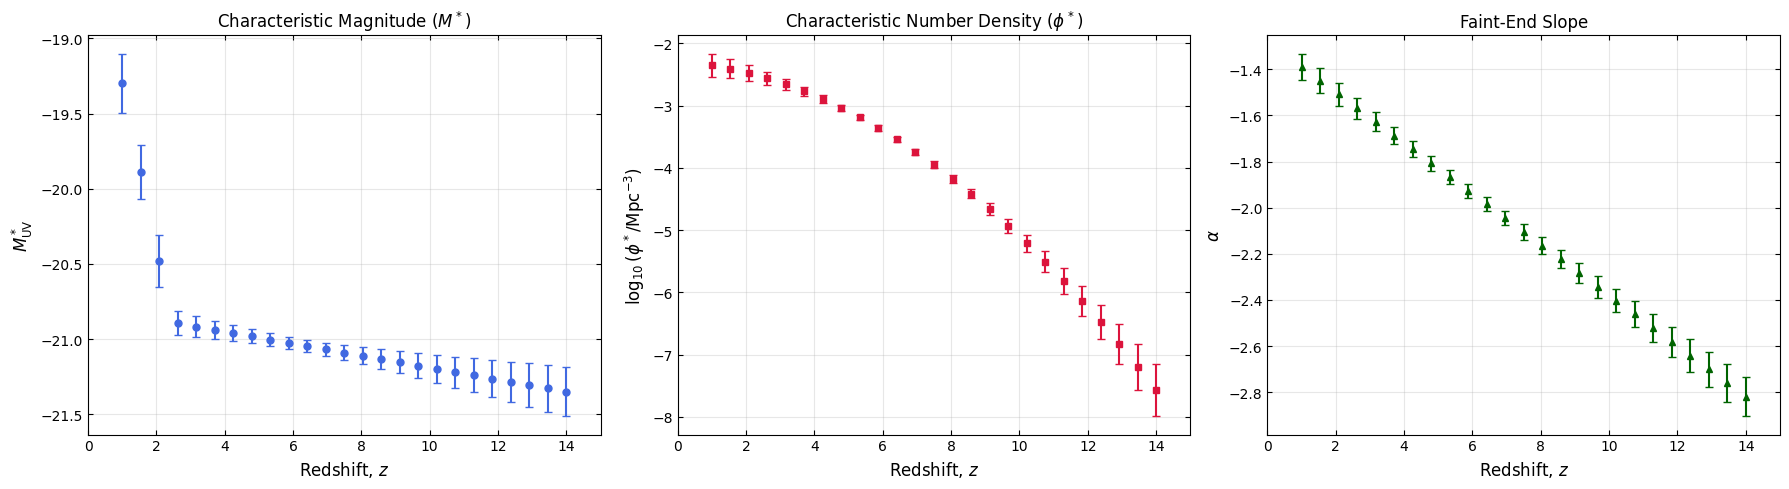

In [31]:
import numpy as np
import matplotlib.pyplot as plt

z = np.linspace(1, 14, 25)
results = [bouwens21_fit(zi) for zi in z]

Mstar, Mstar_err = np.array([r[0] for r in results]).T
logphi, logphi_err = np.array([r[1] for r in results]).T
alpha, alpha_err = np.array([r[2] for r in results]).T

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Characteristic absolute magnitude
axes[0].errorbar(z, Mstar, yerr=Mstar_err, color="royalblue", marker="o", linestyle="none", capsize=3, markersize=5)
axes[0].set_xlabel("Redshift, $z$", fontsize=12)
axes[0].set_ylabel(r"$M^*_{\rm UV}$", fontsize=12)
axes[0].set_title(r"Characteristic Magnitude ($M^*$)")
axes[0].grid(alpha=0.3)

# Characteristic number density
axes[1].errorbar(z, logphi, yerr=logphi_err, color="crimson", marker="s", linestyle="none", capsize=3, markersize=5)
axes[1].set_xlabel("Redshift, $z$", fontsize=12)
axes[1].set_ylabel(r"$\log_{10}(\phi^*/\mathrm{Mpc}^{-3})$", fontsize=12)
axes[1].set_title(r"Characteristic Number Density ($\phi^*$)")
axes[1].grid(alpha=0.3)

# Faint-end slope
axes[2].errorbar(z, alpha, yerr=alpha_err, color="darkgreen", marker="^", linestyle="none", capsize=3, markersize=5)
axes[2].set_xlabel("Redshift, $z$", fontsize=12)
axes[2].set_ylabel(r"$\alpha$", fontsize=12)
axes[2].set_title("Faint-End Slope")
axes[2].grid(alpha=0.3)

for ax in axes:
    ax.tick_params(direction="in", which="both", top=True, right=True)
    ax.set_xlim(0, 15)

plt.tight_layout()
plt.show()